# BÀI TẬP LỚN HỌC MÁY - BÁO CÁO MILESTONE 1
## 01. Phân Tích Dữ Liệu Khám Phá (EDA) & Thiết Kế Pipeline Tiền Xử Lý Chống Data Leakage
---
- **Bộ dữ liệu:** Framingham Heart Study (`data/framingham.csv`)
- **Mục tiêu:** Sàng lọc & Dự báo nguy cơ mắc bệnh tim mạch vành trong 10 năm (`TenYearCHD`)
- **Thành viên phụ trách:** Thành viên 1 (Nhóm trưởng) & Thành viên 3
- **Mốc chấm:** Milestone 1 (Checkpoint Buổi 4) - Bám sát Nhiệm vụ STT 1, 3, 4, 5 trong Bảng Phân Công

In [2]:
# 1. Import các thư viện phân tích và hệ thống
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import trực tiếp từ src
sys.path.append(os.path.abspath('..'))
from src.features import (
    create_features,
    get_preprocessor_pipeline,
    load_and_split_data,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    TARGET_COLUMN
)

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
print('Imports và cấu hình thành công!')

Imports và cấu hình thành công!


## 1. Tải Dữ Liệu & Kiểm Tra Cấu Trúc Tổng Quát
Sử dụng đường dẫn tương đối chuẩn `../data/framingham.csv` theo quy ước của nhóm.

In [3]:
df = pd.read_csv('../data/framingham.csv')
print(f'Kích thước bộ dữ liệu ban đầu: {df.shape[0]} dòng x {df.shape[1]} cột')
df.head()

Kích thước bộ dữ liệu ban đầu: 4240 dòng x 16 cột


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [4]:
# Thống kê mô tả các biến số
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


## 2. Kiểm Tra Dữ Liệu Thiếu (Missing Values)
Phát hiện các cột có dữ liệu thiếu để thiết kế chiến lược điền khuyết (Imputation) phù hợp.

In [5]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Số lượng khuyết': missing, 'Tỷ lệ (%)': missing_pct})
missing_df = missing_df[missing_df['Số lượng khuyết'] > 0].sort_values('Số lượng khuyết', ascending=False)

print(f'Tổng số giá trị bị khuyết: {df.isnull().sum().sum()}')
print(f'Số lượng cột bị khuyết: {len(missing_df)} / {df.shape[1]}')
missing_df

Tổng số giá trị bị khuyết: 645
Số lượng cột bị khuyết: 7 / 16


,Số lượng khuyết,Tỷ lệ (%)
glucose,388,9.15
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


## 3. Trực Quan Hóa Dữ Liệu Khám Phá (EDA)
Phân tích phân phối lớp mục tiêu `TenYearCHD`, các biến số lâm sàng và mối tương quan giữa các đặc trưng.

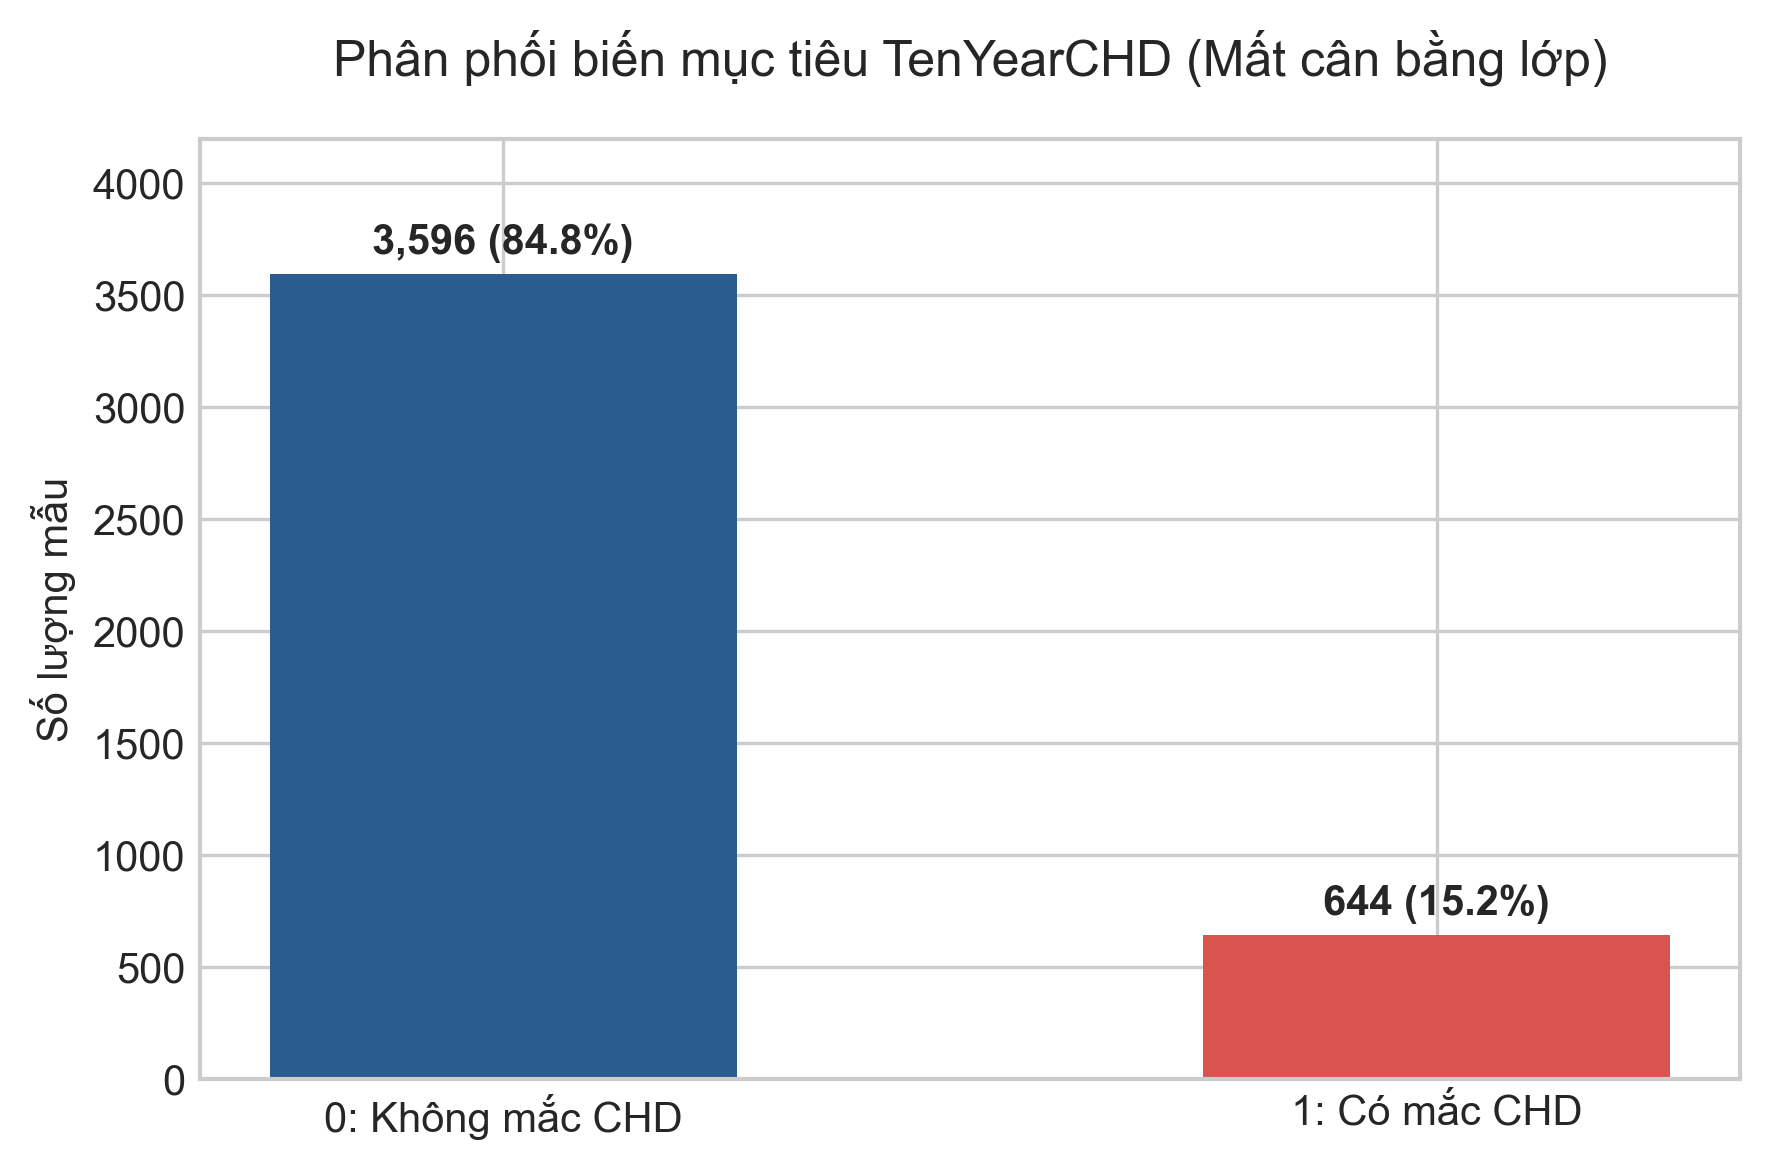

In [7]:
# 3.1. Phân phối biến mục tiêu TenYearCHD (Mất cân bằng dữ liệu)
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
counts = df[TARGET_COLUMN].value_counts()
colors = ['#2b5c8f', '#d9534f']
bars = ax.bar(['0: Không mắc CHD', '1: Có mắc CHD'], counts.values, color=colors, width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{yval:,} ({yval/len(df):.1%})', 
            ha='center', va='bottom', fontweight='bold')

ax.set_title('Phân phối biến mục tiêu TenYearCHD (Mất cân bằng lớp)', fontsize=12, pad=15)
ax.set_ylabel('Số lượng mẫu')
ax.set_ylim(0, 4200)
plt.tight_layout()
plt.show()

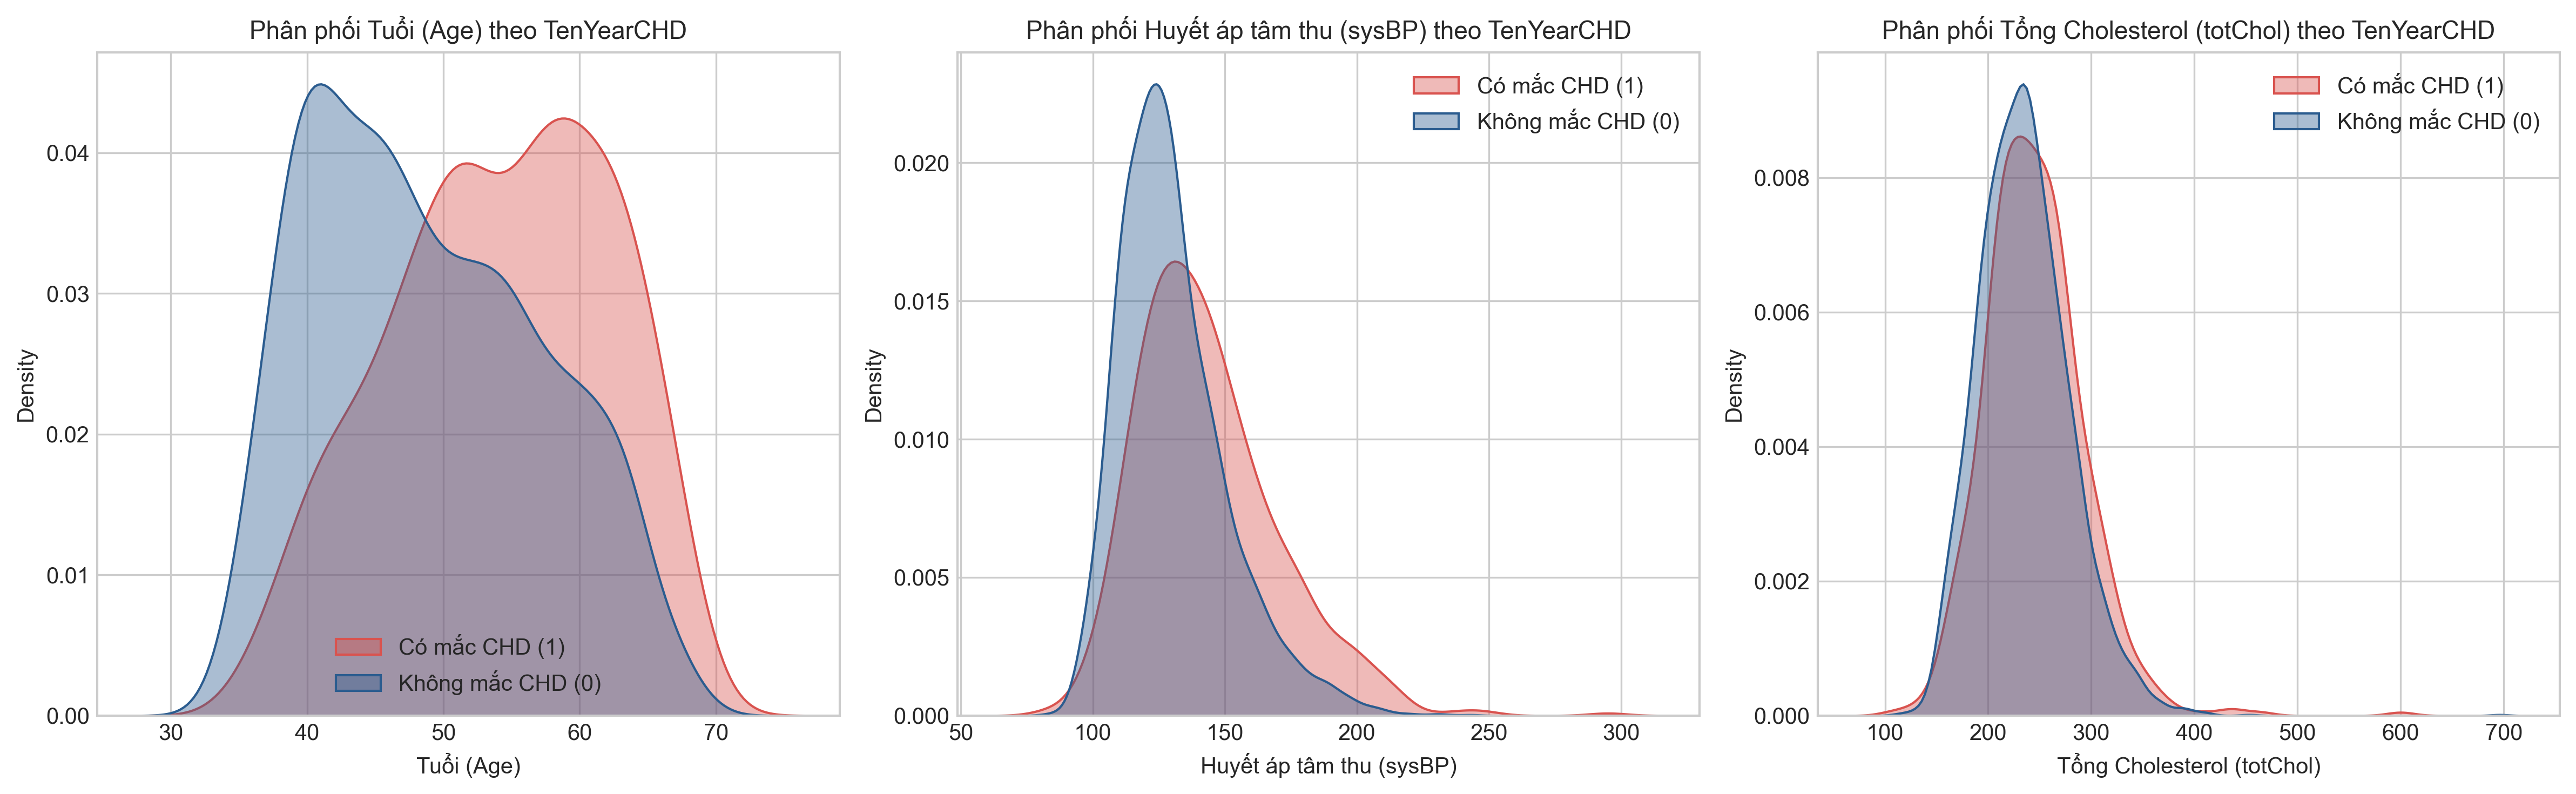

In [8]:
# 3.2. Phân phối tuổi, huyết áp, cholesterol theo nhóm mắc bệnh
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
features_plot = [('age', 'Tuổi (Age)'), ('sysBP', 'Huyết áp tâm thu (sysBP)'), ('totChol', 'Tổng Cholesterol (totChol)')]

for i, (col, label) in enumerate(features_plot):
    sns.kdeplot(data=df, x=col, hue=TARGET_COLUMN, common_norm=False, 
                palette=['#2b5c8f', '#d9534f'], fill=True, alpha=0.4, ax=axes[i])
    axes[i].set_title(f'Phân phối {label} theo TenYearCHD', fontsize=11)
    axes[i].set_xlabel(label)
    axes[i].legend(['Có mắc CHD (1)', 'Không mắc CHD (0)'])

plt.tight_layout()
plt.show()

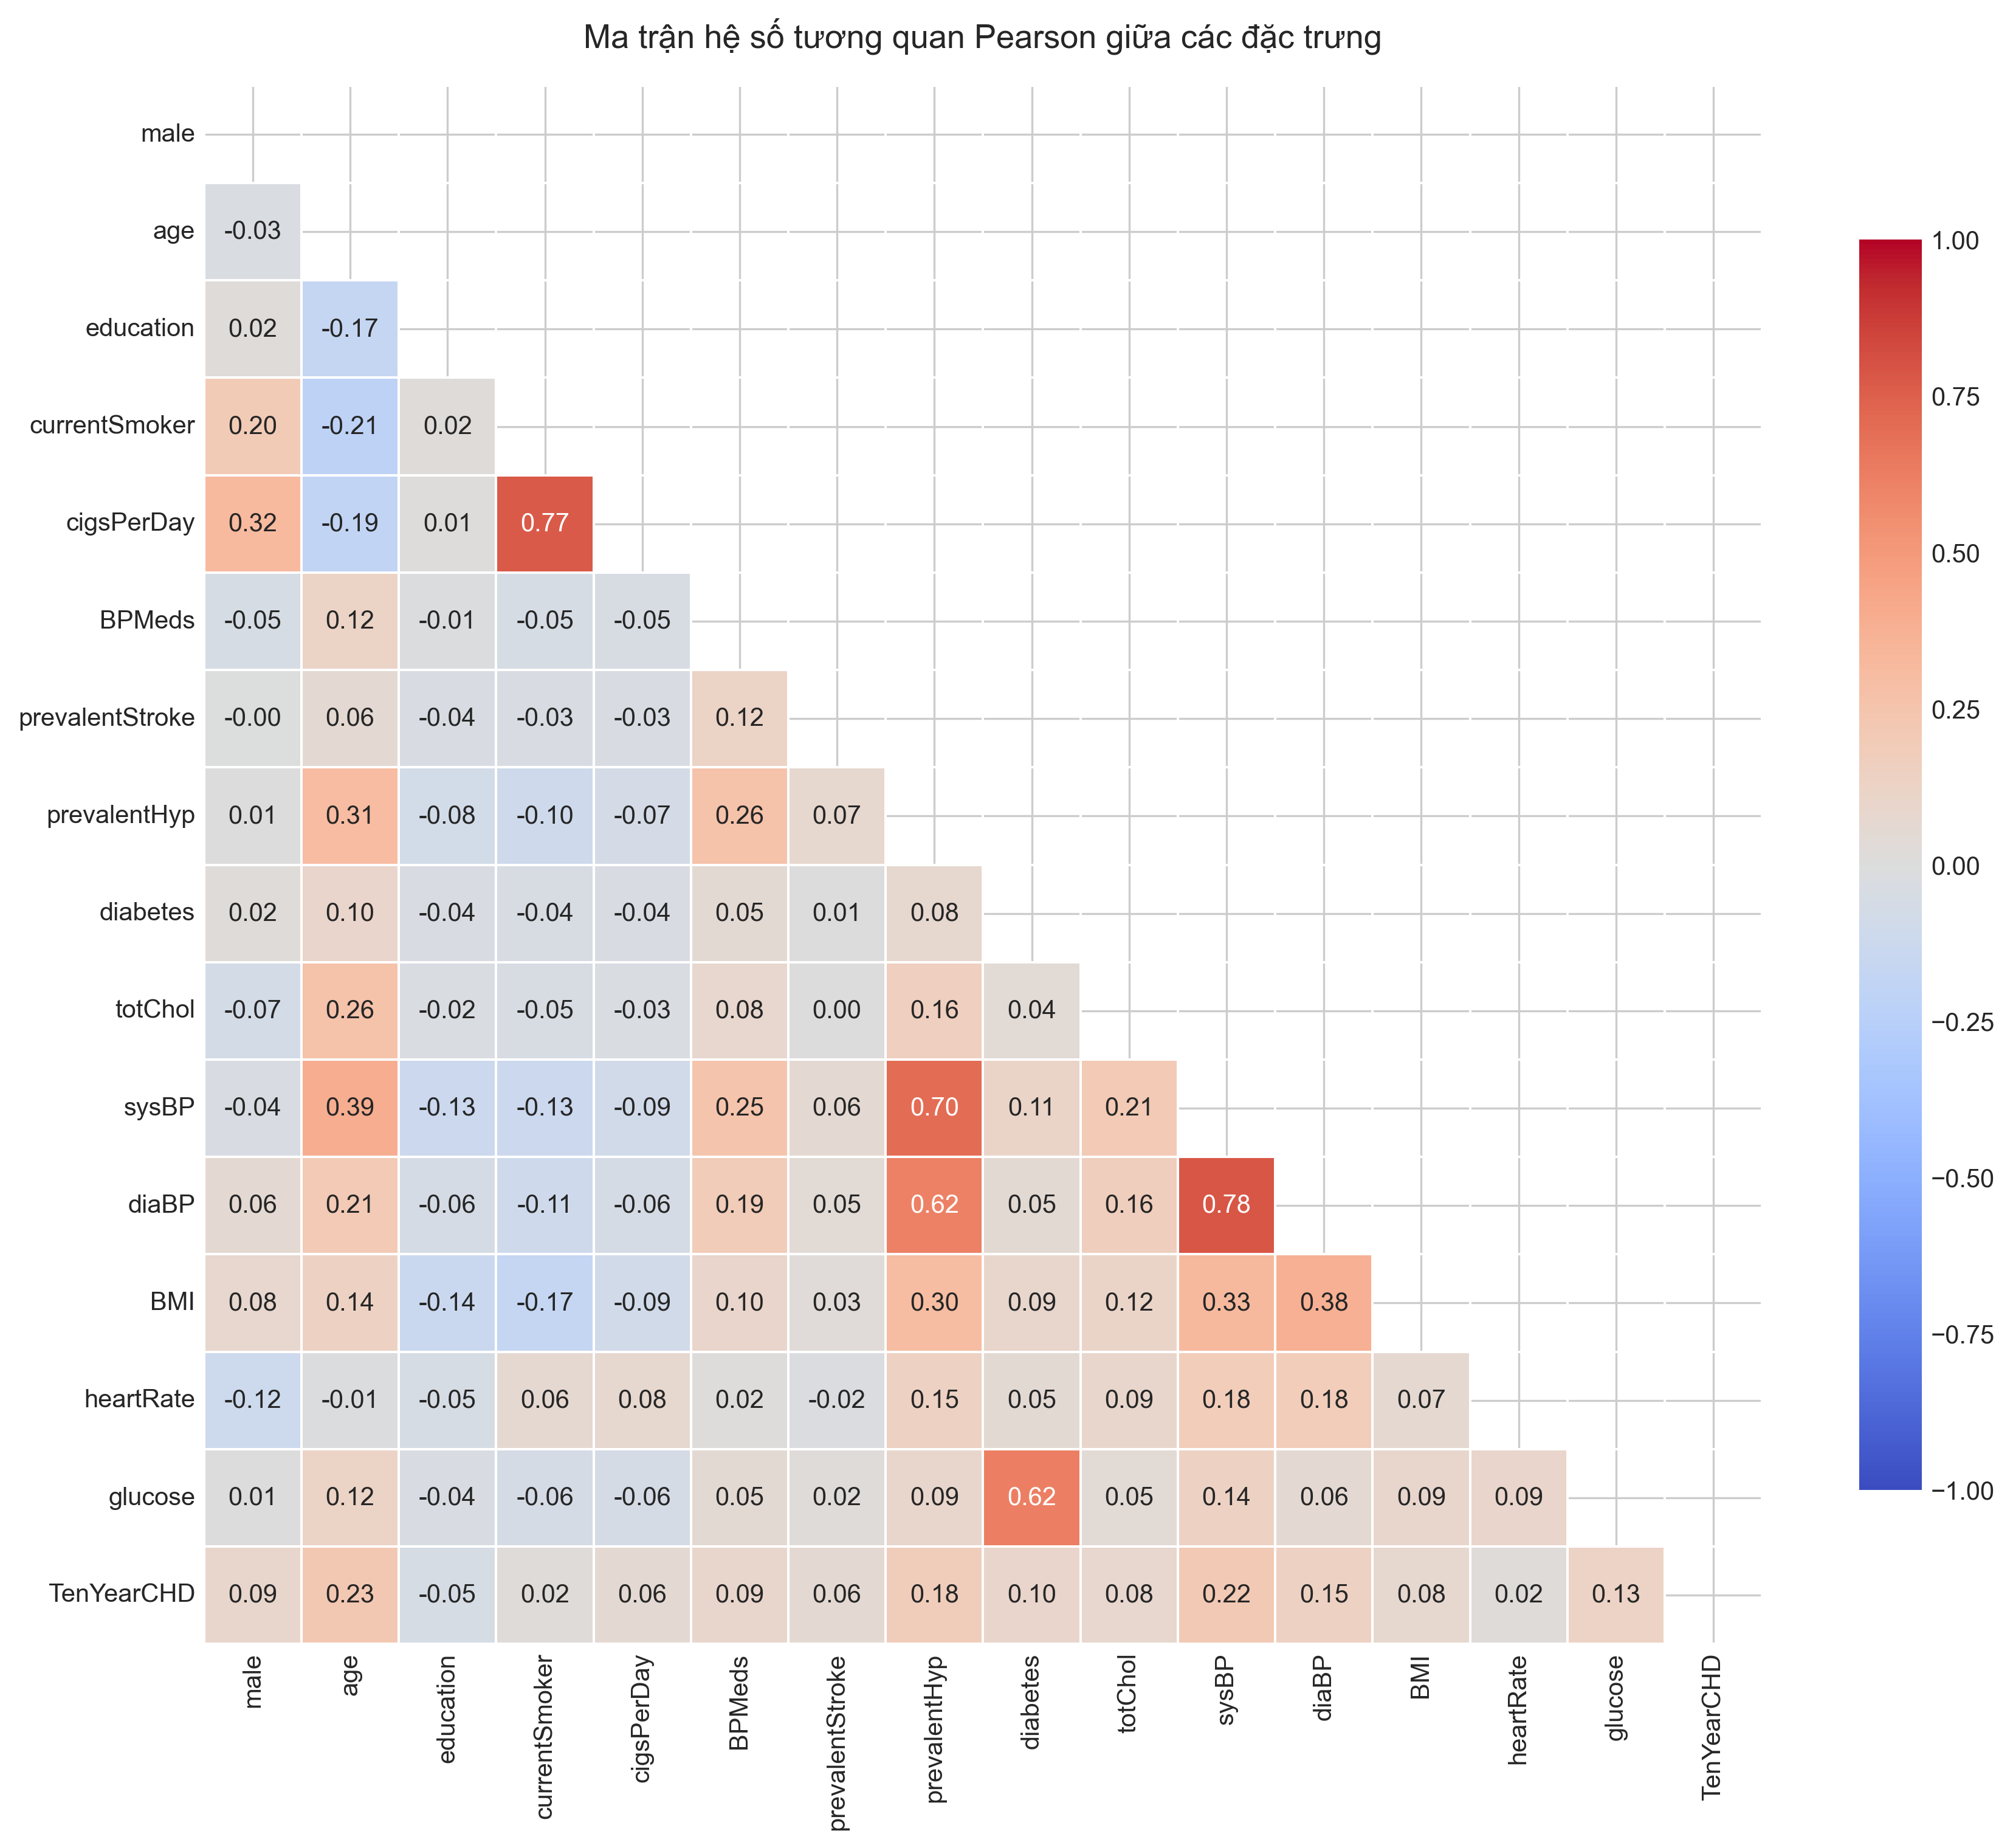

In [9]:
# 3.3. Ma trận tương quan (Correlation Matrix Heatmap)
fig, ax = plt.subplots(figsize=(12, 10), dpi=300)
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            center=0, square=True, linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Ma trận hệ số tương quan Pearson giữa các đặc trưng', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

> **Nhận xét quan trọng:**
> 1. **Tương quan mạnh giữa huyết áp tâm thu (`sysBP`) và tâm trương (`diaBP`)**: Hệ số tương quan $r = 0.78$. Cả hai phản ánh tình trạng áp lực lòng mạch. Do đó, việc kết hợp thành các chỉ số y khoa như **Áp lực mạch (Pulse Pressure)** và **Huyết áp trung bình (MAP)** là có cơ sở khoa học vững chắc.
> 2. **Tương quan giữa `currentSmoker` và `cigsPerDay`** ($r = 0.77$): Người hút thuốc có nguy cơ cao hơn khi tuổi tác tăng lên. Đặc trưng tích hợp `age_cigs_interaction` sẽ nắm bắt hiệu ứng tương tác này.

---
## 4. Kỹ Thuật Tạo Đặc Trưng Mới (Feature Engineering - STT 5)
Dựa trên kiến thức chuyên môn tim mạch và phân tích EDA ở trên, ta tạo 3 đặc trưng mới:
1. **`pulse_pressure` (Áp lực mạch):**
   $$\text{pulse\_pressure} = \text{sysBP} - \text{diaBP}$$
   *Ý nghĩa y học:* Độ chênh lệch phản ánh độ cứng thành động mạch. Áp lực mạch cao (> 60 mmHg) là yếu tố độc lập dự báo xơ vữa động mạch và đột quỵ.
2. **`MAP` (Mean Arterial Pressure - Huyết áp động mạch trung bình):**
   $$\text{MAP} = \text{diaBP} + \frac{\text{sysBP} - \text{diaBP}}{3}$$
   *Ý nghĩa y học:* Áp lực tưới máu thực tế liên tục đến các cơ quan quan trọng, toàn diện hơn huyết áp đơn lẻ.
3. **`age_cigs_interaction` (Tương tác Tuổi x Lượng thuốc lá):**
   $$\text{age\_cigs\_interaction} = \text{age} \times \text{cigsPerDay}$$
   *Ý nghĩa y học:* Mức độ phơi nhiễm độc chất khói thuốc theo thời gian tích lũy theo số năm tuổi.

In [20]:
# Thử nghiệm hàm create_features từ module src/features.py
df_featured = create_features(df)
print('3 đặc trưng mới đã được bổ sung vào DataFrame:')
df_featured[['sysBP', 'diaBP', 'pulse_pressure', 'MAP', 'age', 'cigsPerDay', 'age_cigs_interaction']].head()

3 đặc trưng mới đã được bổ sung vào DataFrame:


,sysBP,diaBP,pulse_pressure,MAP,age,cigsPerDay,age_cigs_interaction
0,106.0,70.0,36.0,82.000000,39,0.0,0.0
1,121.0,81.0,40.0,94.333333,46,0.0,0.0
2,127.5,80.0,47.5,95.833333,48,20.0,960.0
3,150.0,95.0,55.0,113.333333,61,30.0,1830.0
4,130.0,84.0,46.0,99.333333,46,23.0,1058.0


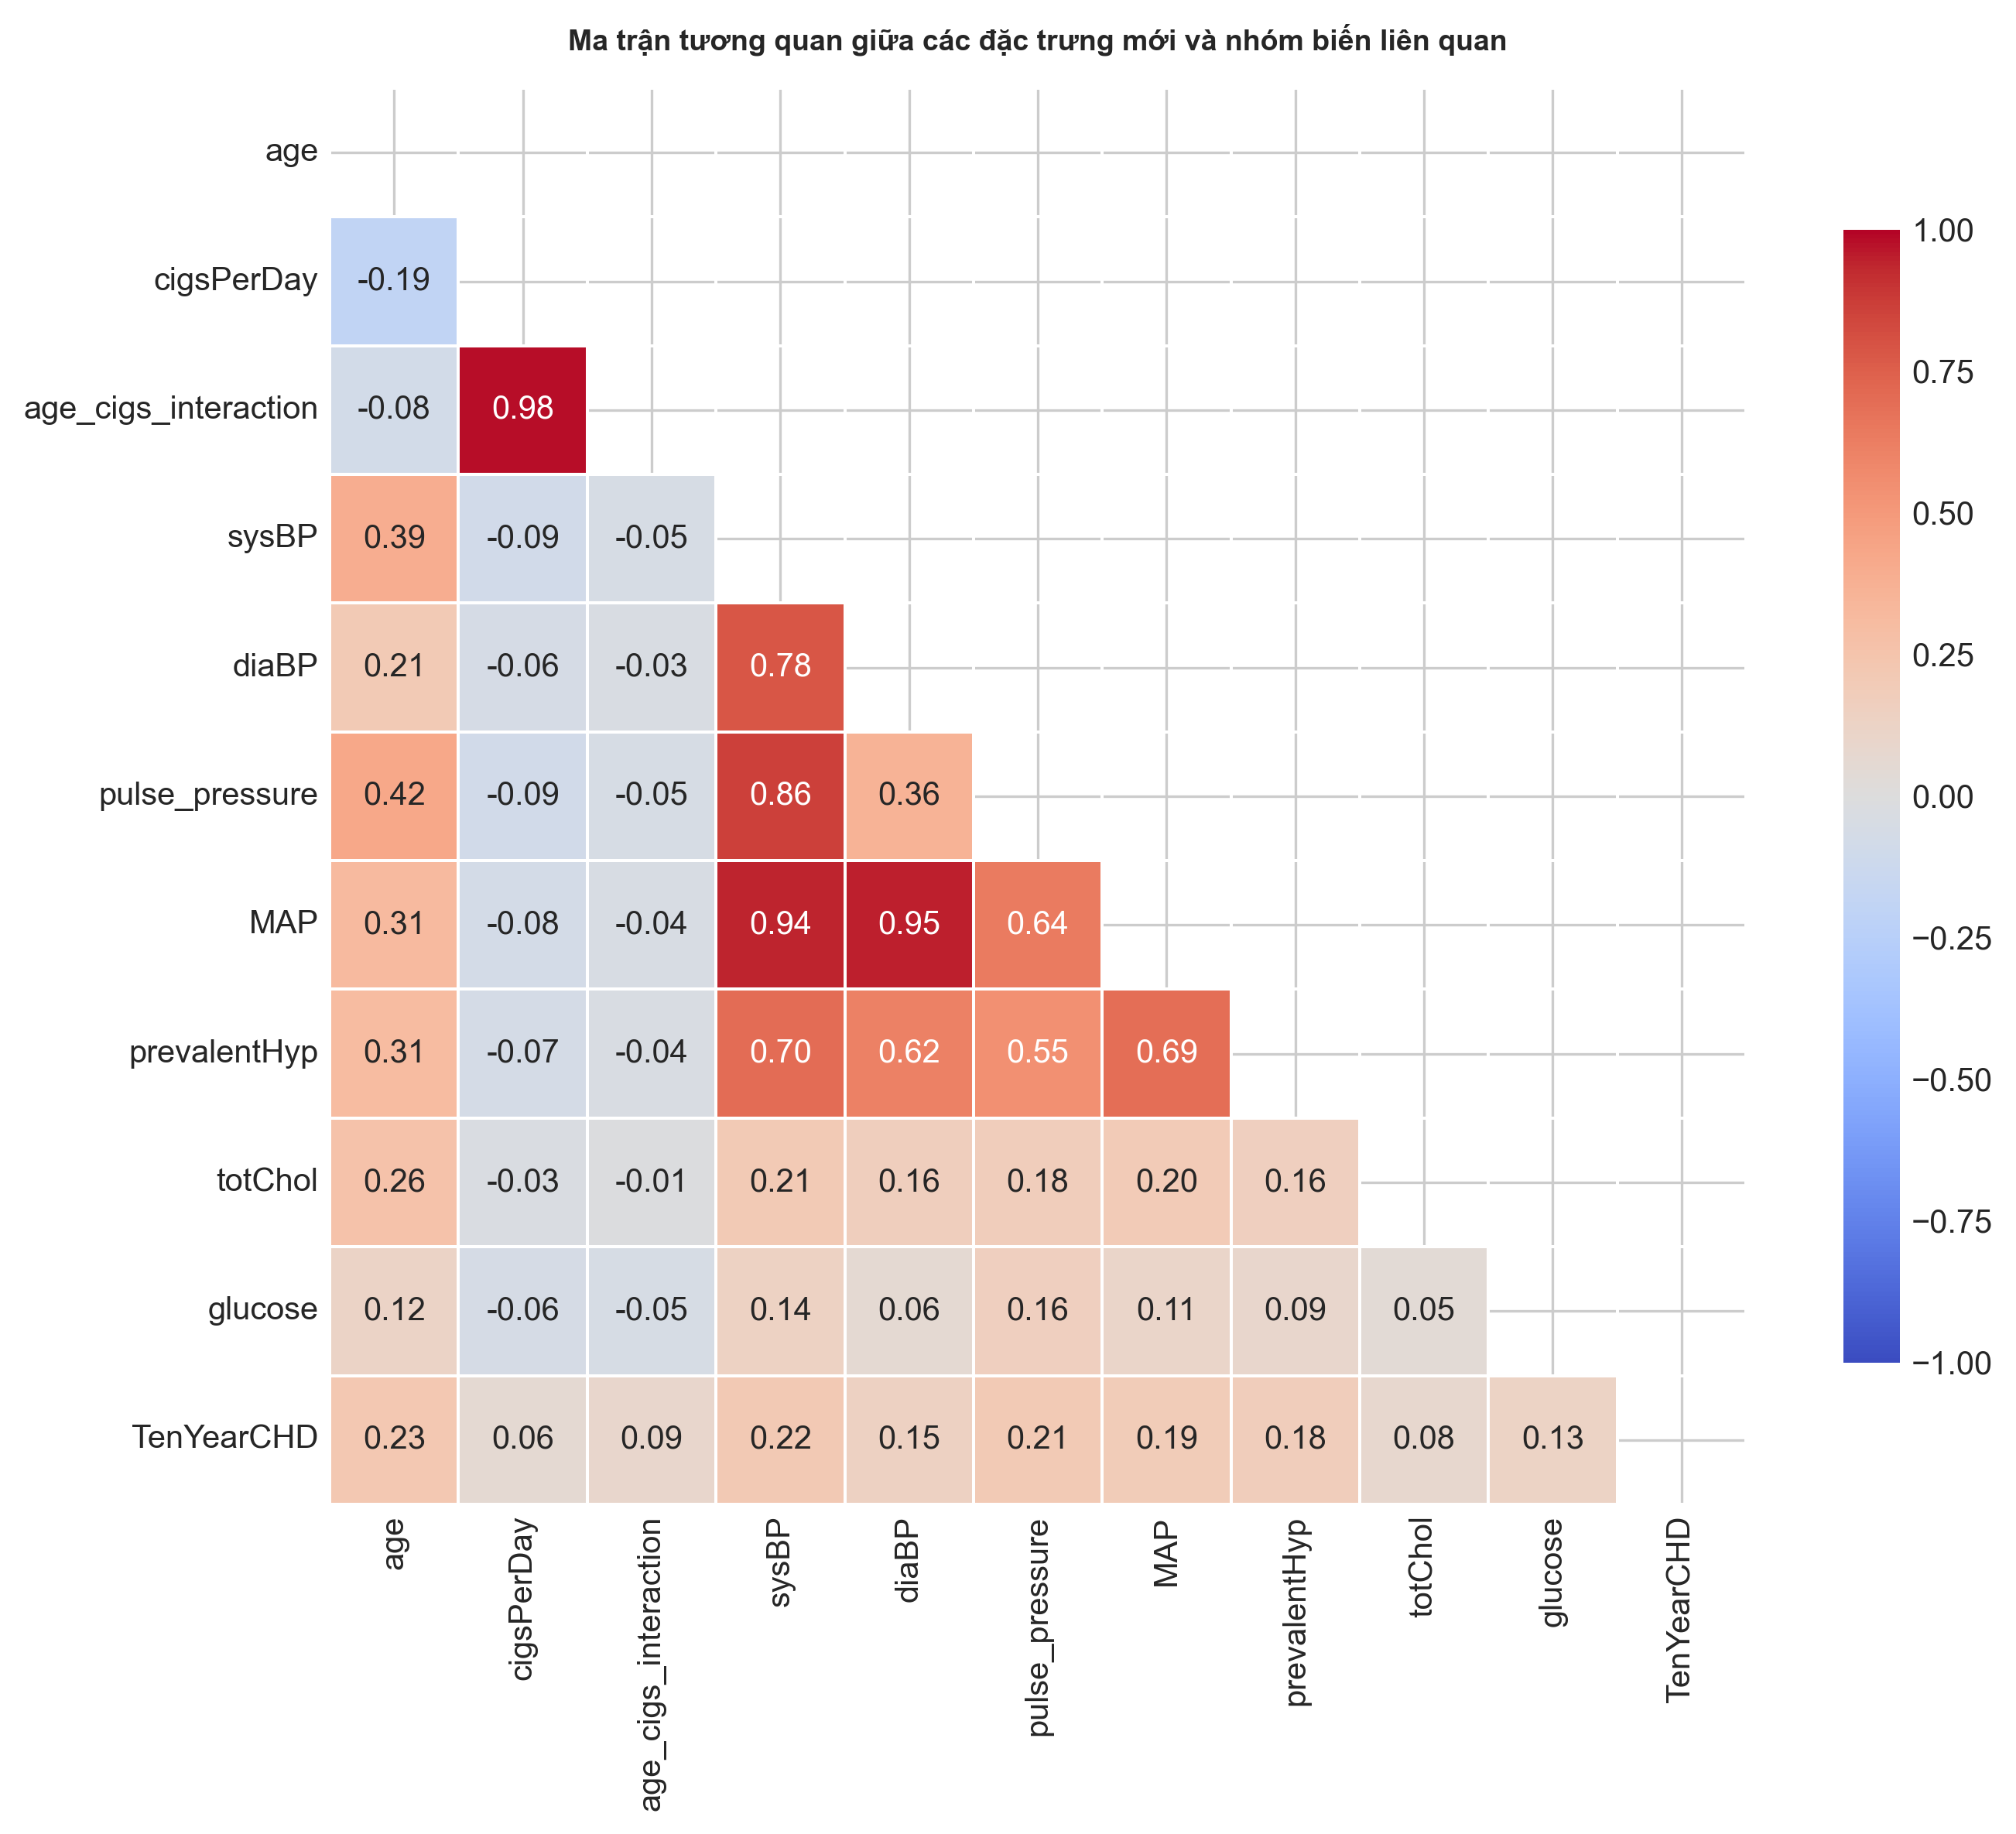

In [19]:
#VẼ MA TRẬN TƯƠNG QUAN
# Chọn các biến gốc liên quan, 3 đặc trưng mới và biến mục tiêu TenYearCHD
cols_fe_corr = [
    'age', 'cigsPerDay', 'age_cigs_interaction',
    'sysBP', 'diaBP', 'pulse_pressure', 'MAP',
    'prevalentHyp', 'totChol', 'glucose', 'TenYearCHD'
]

plt.figure(figsize=(10, 8), dpi=300)
corr_fe = df_featured[cols_fe_corr].corr()
mask = np.triu(np.ones_like(corr_fe, dtype=bool))

sns.heatmap(
    corr_fe, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}
)
plt.title('Ma trận tương quan giữa các đặc trưng mới và nhóm biến liên quan', fontsize=9, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

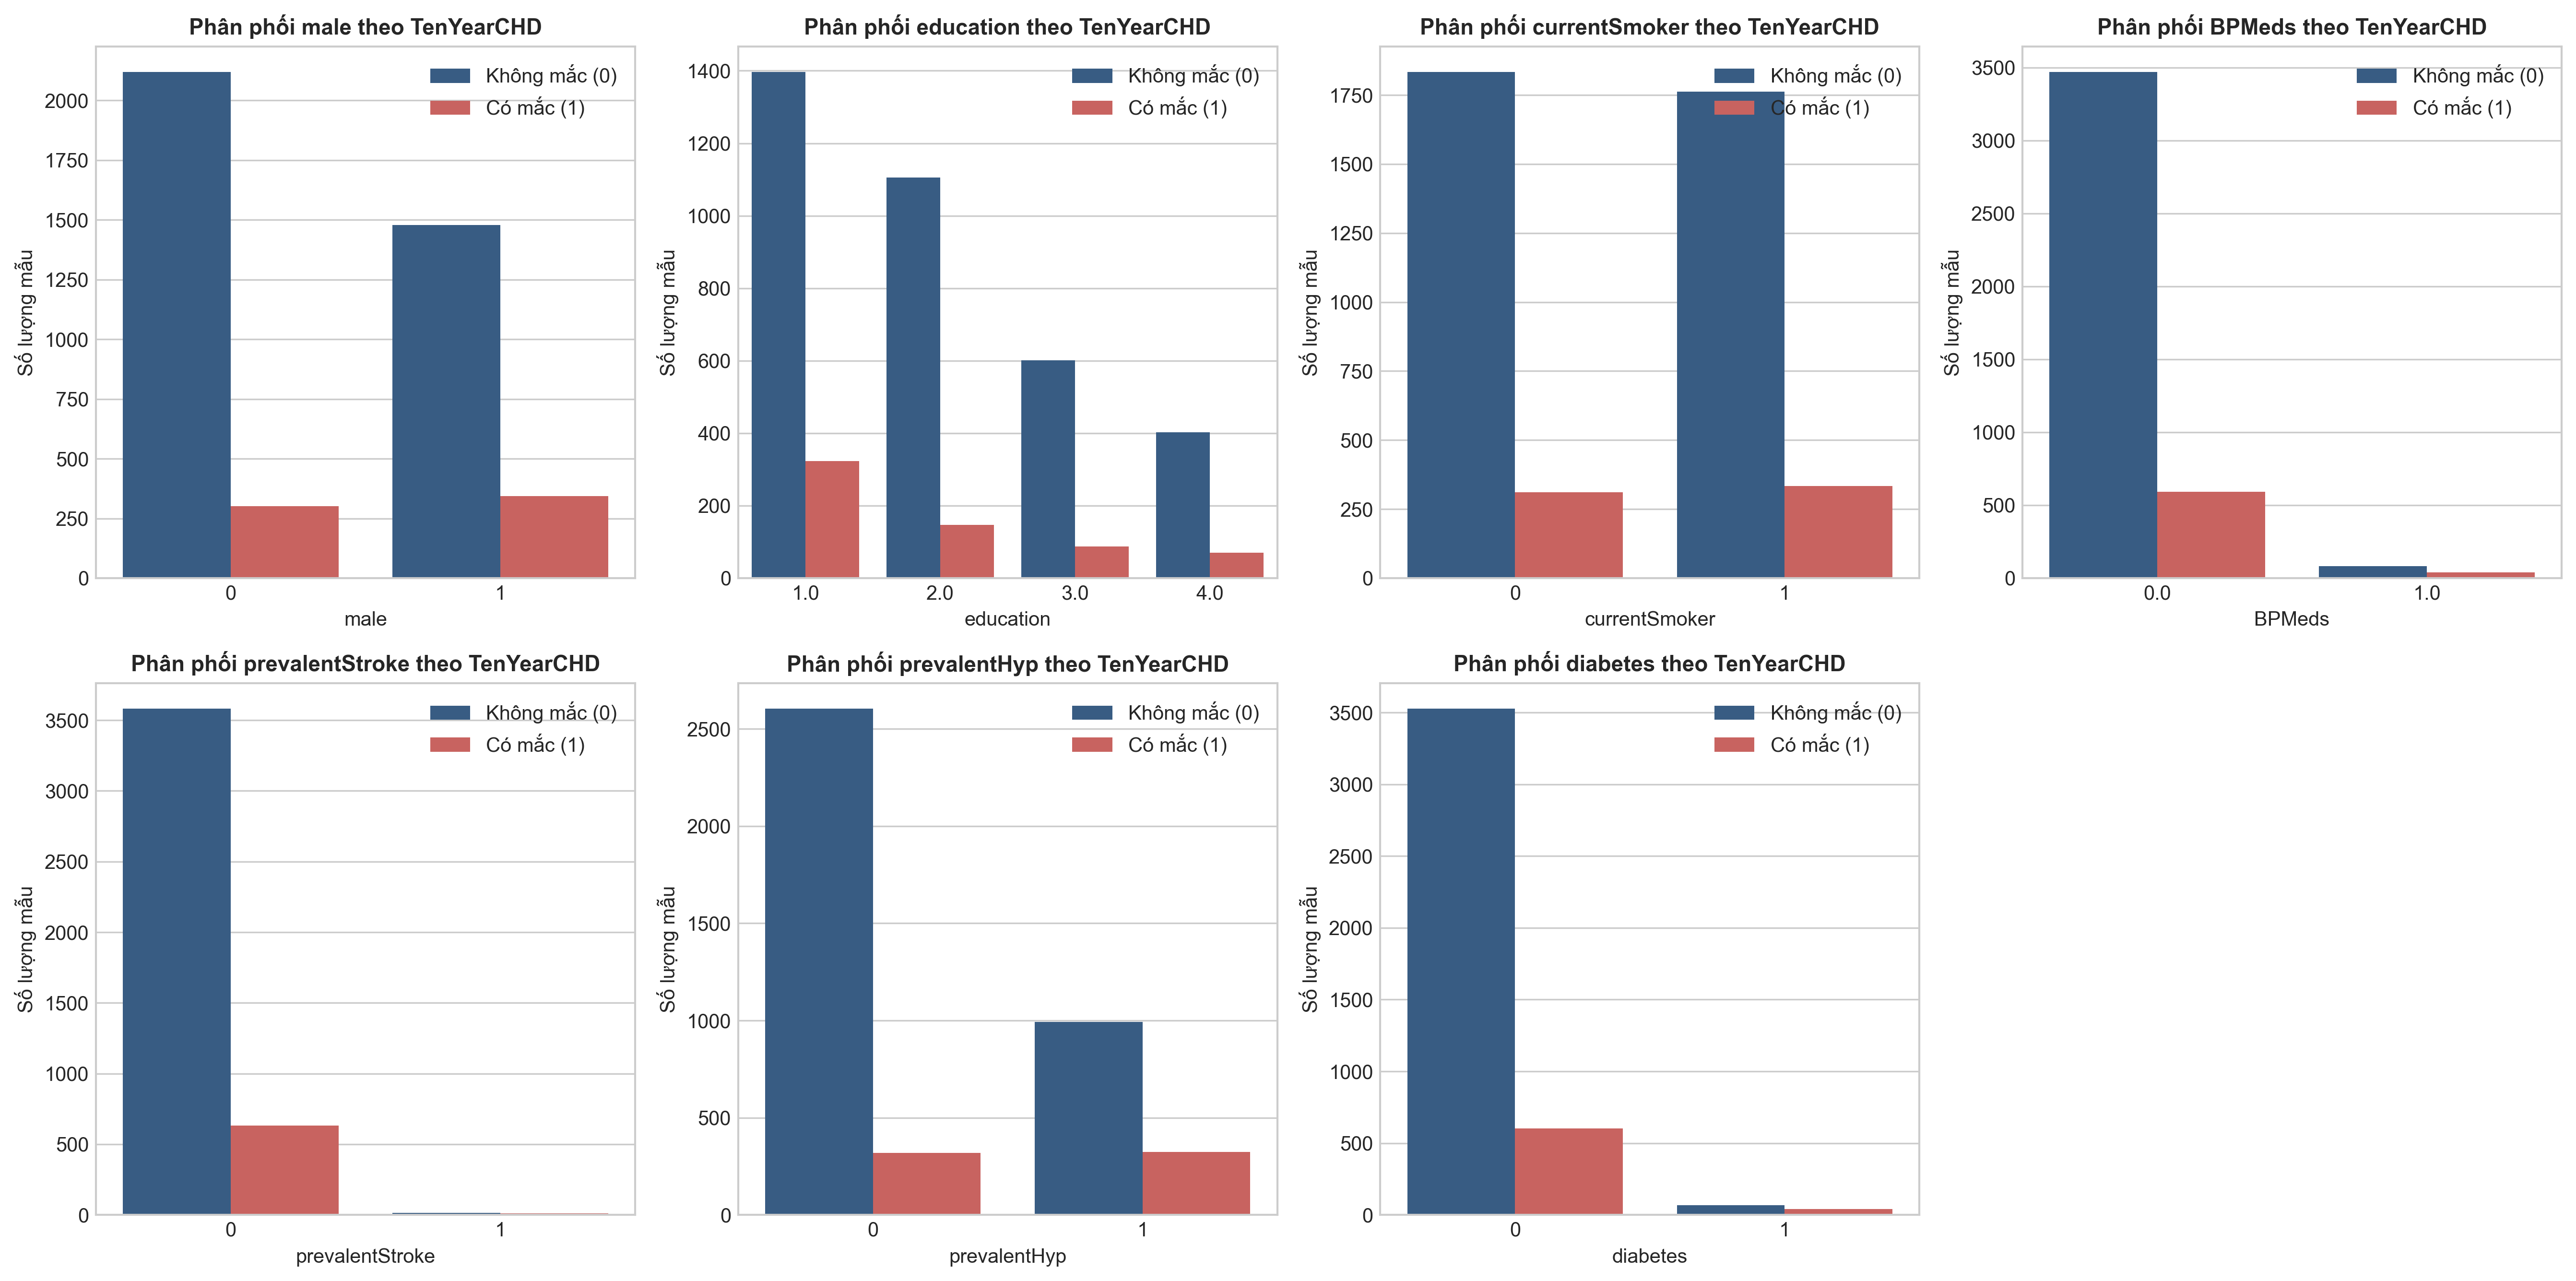

TỶ LỆ MẮC BỆNH TIM (TenYearCHD = 1) THEO TỪNG BIẾN PHÂN LOẠI (%)

* Biến male:
  - Nhóm 0: 12.44%
  - Nhóm 1: 18.85%

* Biến education:
  - Nhóm 1.0: 18.78%
  - Nhóm 2.0: 11.73%
  - Nhóm 3.0: 12.77%
  - Nhóm 4.0: 14.80%

* Biến currentSmoker:
  - Nhóm 0: 14.50%
  - Nhóm 1: 15.89%

* Biến BPMeds:
  - Nhóm 0.0: 14.57%
  - Nhóm 1.0: 33.06%

* Biến prevalentStroke:
  - Nhóm 0: 15.02%
  - Nhóm 1: 44.00%

* Biến prevalentHyp:
  - Nhóm 0: 10.91%
  - Nhóm 1: 24.68%

* Biến diabetes:
  - Nhóm 0: 14.62%
  - Nhóm 1: 36.70%


In [22]:
# Phân tích các biến phân loại (hút thuốc, tiểu đường, cao huyết áp...) theo nhóm bệnh TenYearCHD
cat_cols = ['male', 'education', 'currentSmoker', 'BPMeds', 
            'prevalentStroke', 'prevalentHyp', 'diabetes']

fig, axes = plt.subplots(2, 4, figsize=(18, 9), dpi=300)
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(
        data=df_featured, x=col, hue='TenYearCHD',
        palette=['#2b5c8f', '#d9534f'], ax=axes[i]
    )
    axes[i].set_title(f'Phân phối {col} theo TenYearCHD', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Số lượng mẫu')
    axes[i].legend(['Không mắc (0)', 'Có mắc (1)'], loc='upper right')

fig.delaxes(axes[7])
plt.tight_layout()
plt.show()

# Tính tỷ lệ (%) mắc bệnh tim trong từng nhóm phân loại
print("TỶ LỆ MẮC BỆNH TIM (TenYearCHD = 1) THEO TỪNG BIẾN PHÂN LOẠI (%)")
for col in cat_cols:
    rate = df_featured.groupby(col)['TenYearCHD'].mean() * 100
    print(f"\n* Biến {col}:")
    for val, pct in rate.items():
        print(f"  - Nhóm {val}: {pct:.2f}%")

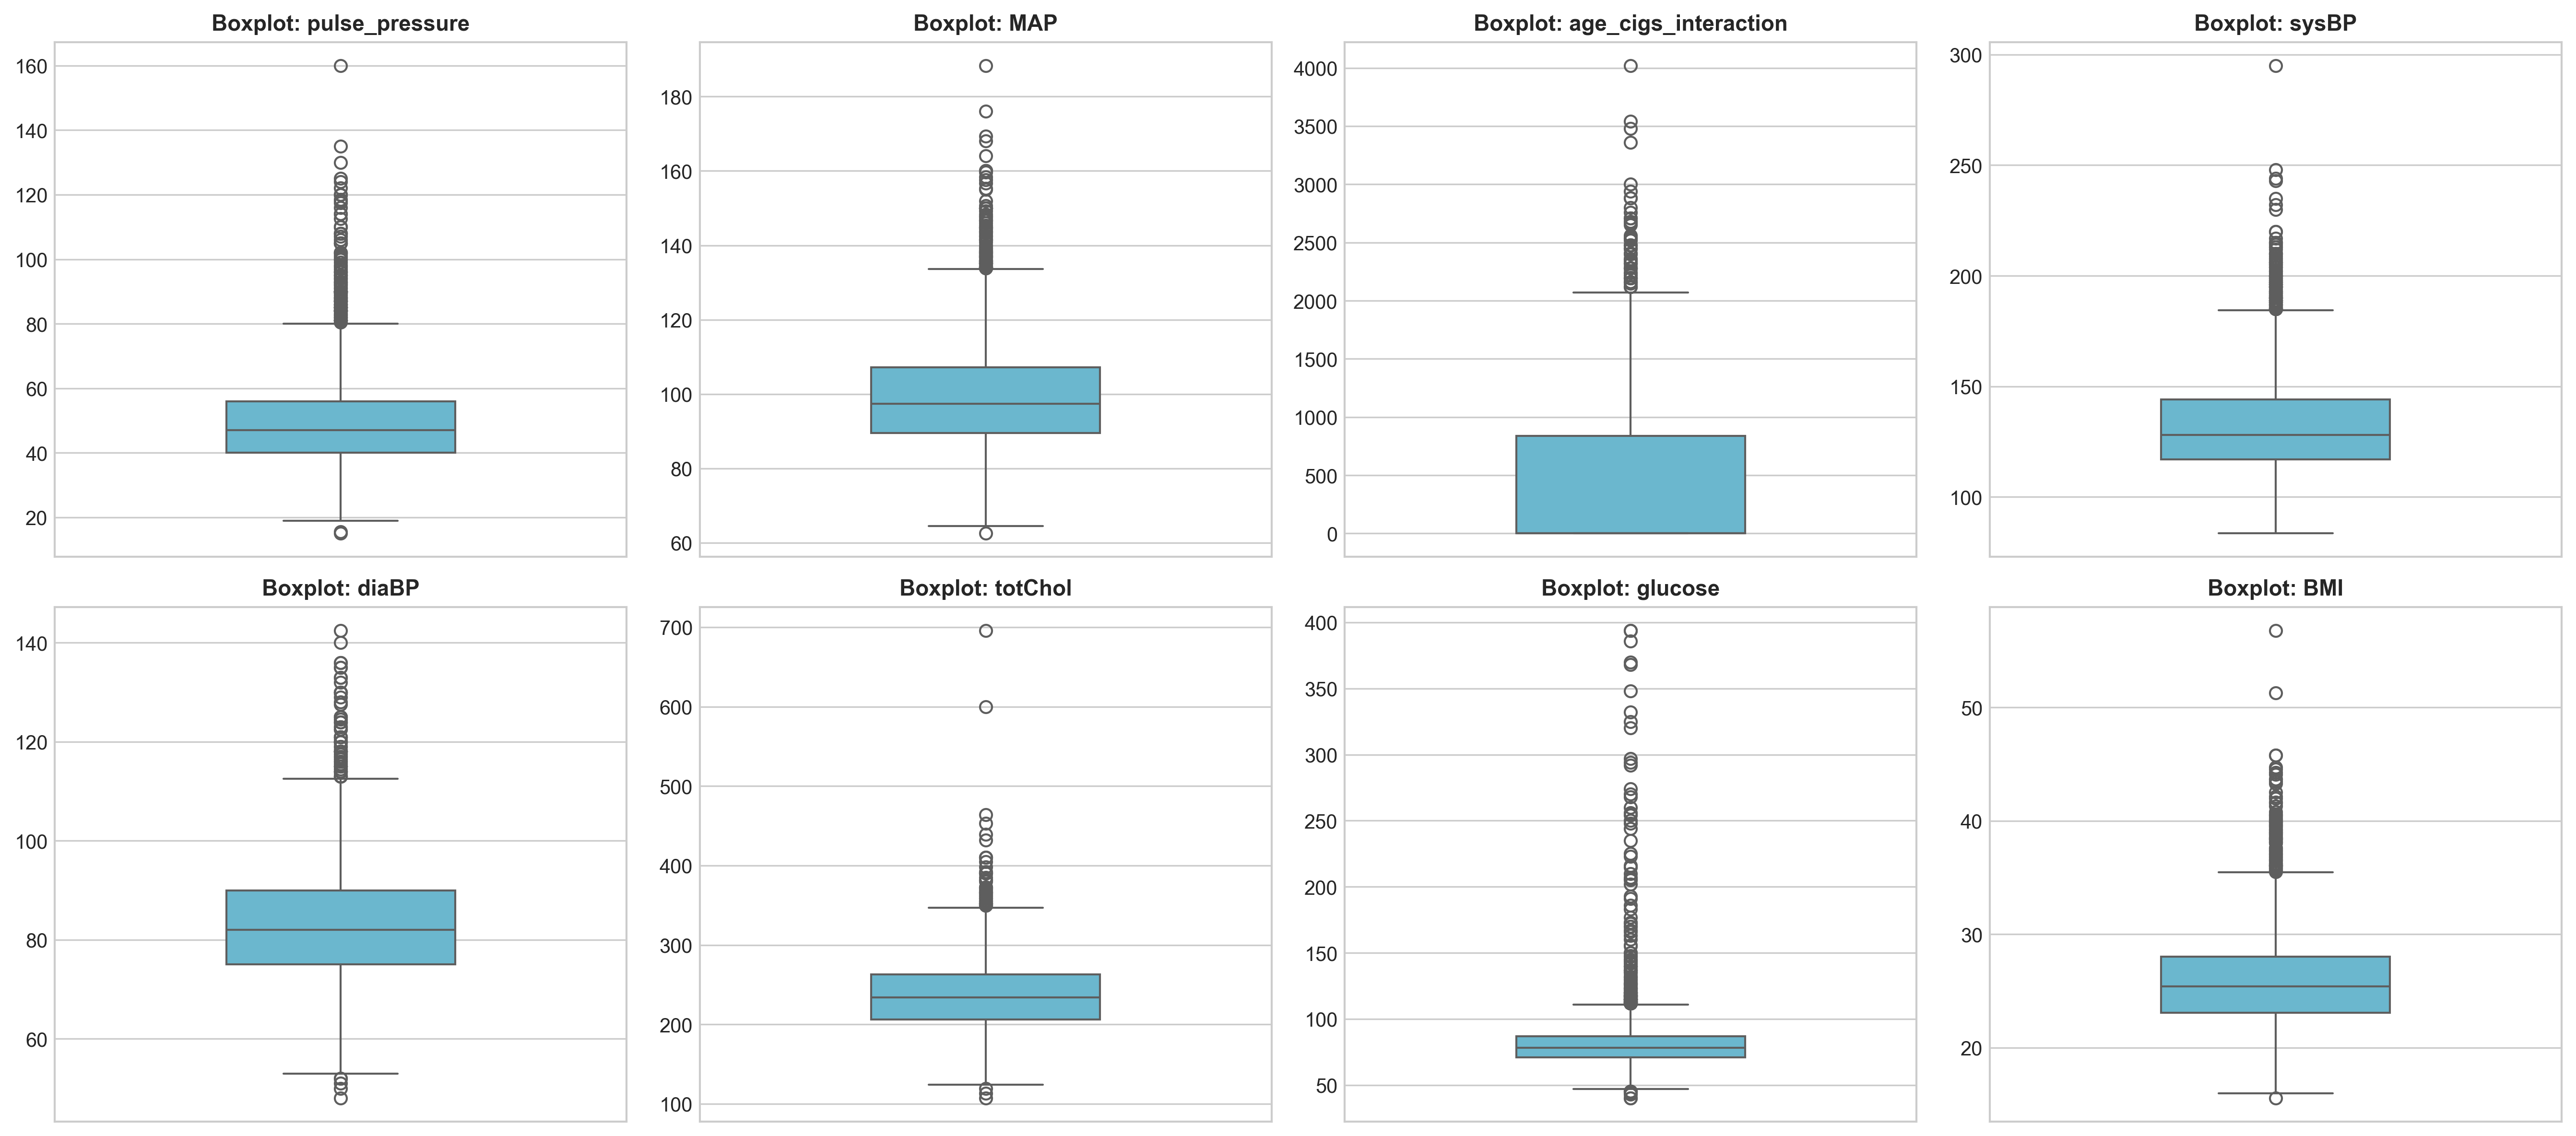

Nhận biết outliers theo quy tắc IQR (Q1 - 1.5*IQR, Q3 + 1.5*IQR):
THỐNG KÊ OUTLIERS
pulse_pressure        : 168 outliers (3.96%) | Ngưỡng trên = 80.0
MAP                   : 110 outliers (2.59%) | Ngưỡng trên = 133.7
age_cigs_interaction  :  56 outliers (1.32%) | Ngưỡng trên = 2091.2
sysBP                 : 126 outliers (2.97%) | Ngưỡng trên = 184.5
diaBP                 :  77 outliers (1.82%) | Ngưỡng trên = 112.5
totChol               :  56 outliers (1.32%) | Ngưỡng trên = 348.5
glucose               : 188 outliers (4.43%) | Ngưỡng trên = 111.0
BMI                   :  97 outliers (2.29%) | Ngưỡng trên = 35.5


In [24]:
# Kiểm tra giá trị ngoại lai (Outliers) của các biến số và 3 đặc trưng mới tạo
outlier_cols = ['pulse_pressure', 'MAP', 'age_cigs_interaction', 
                'sysBP', 'diaBP', 'totChol', 'glucose', 'BMI']

fig, axes = plt.subplots(2, 4, figsize=(18, 8), dpi=300)
axes = axes.flatten()

for i, col in enumerate(outlier_cols):
    sns.boxplot(data=df_featured, y=col, color='#5bc0de', width=0.4, ax=axes[i])
    axes[i].set_title(f'Boxplot: {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

print("Nhận biết outliers theo quy tắc IQR (Q1 - 1.5*IQR, Q3 + 1.5*IQR):")

# Thống kê số lượng Outliers
print("THỐNG KÊ OUTLIERS")
for col in outlier_cols:
    Q1 = df_featured[col].quantile(0.25)
    Q3 = df_featured[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df_featured[col] < lower) | (df_featured[col] > upper)).sum()
    print(f"{col:22s}: {n_out:3d} outliers ({n_out/len(df_featured)*100:.2f}%) | Ngưỡng trên = {upper:.1f}")

> **Nhận xét giá trị ngoại lai (ouliers):**
> - **age** phân bố đều và không có ngoại lai.
> - Hầu hết các biến lâm sàng **(glucose, sysBP, diaBP, totChol, BMI)** và 3 đặc trưng mới tạo **(pulse_pressure, MAP, age_cigs_interaction)** đều xuất hiện nhiều điểm ngoại lai lệch về phía trên, cao vượt ngưỡng trên IQR.
> - Các điểm vượt ngưỡng này là chỉ số bệnh lý có thật của bệnh nhân (cao huyết áp nặng, đường huyết hoặc mỡ máu cao), nên là không cần phải xóa số liệu Outliers này. Sau khi chia Train/Test, đề xuất dùng RobustScaler (chuẩn hóa theo trung vị và IQR) để hạn chế ảnh hưởng của các điểm ngoại lai này lên mô hình.

---
## 5. Chia Tập Dữ Liệu Train / Test (Tuân Thủ Tuyệt Đối Quy Ước 1 & 2)
> ⚠️ **LƯU Ý BẮT BUỘC ĐỂ KHÔNG BỊ TRỪ ĐIỂM (Data Leakage):**
> - BẮT BUỘC thực hiện chia tập Train (80%) và Test (20%) bằng `train_test_split` trước khi thực hiện bất kỳ phép `fit` nào của Imputer hoặc Scaler.
> - Dùng `stratify=y` và `random_state=42` để cố định dữ liệu và bảo toàn tỷ lệ nhãn cho cả 3 máy.

In [8]:
# Gọi hàm load_and_split_data chuẩn từ module src/features.py
X_train, X_test, y_train, y_test = load_and_split_data(
    data_path='../data/framingham.csv',
    test_size=0.2,
    random_state=42
)

print(f'Kích thước X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'Kích thước X_test:  {X_test.shape}  | y_test:  {y_test.shape}')
print(f'Tỷ lệ nhãn dương (TenYearCHD=1) trên Train: {y_train.mean():.4f}')
print(f'Tỷ lệ nhãn dương (TenYearCHD=1) trên Test:  {y_test.mean():.4f}')

Kích thước X_train: (3392, 15) | y_train: (3392,)
Kích thước X_test:  (848, 15)  | y_test:  (848,)
Tỷ lệ nhãn dương (TenYearCHD=1) trên Train: 0.1518
Tỷ lệ nhãn dương (TenYearCHD=1) trên Test:  0.1521


---
## 6. Đóng Gói Bộ Tiền Xử Lý Pipeline (ColumnTransformer) Chống Rò Rỉ Dữ Liệu
Toàn bộ quy trình tiền xử lý được đóng gói trong một `Pipeline` duy nhất gồm:
1. **`HeartDiseaseFeatureEngineer`:** Tự động tính toán 3 đặc trưng mới trên dữ liệu.
2. **`ColumnTransformer`:**
   - **11 Đặc trưng số:** `SimpleImputer(strategy='median')` -> `StandardScaler()`
   - **7 Đặc trưng phân loại:** `SimpleImputer(strategy='most_frequent')`

**Cơ chế chống Data Leakage:**
- `pipeline.fit(X_train)`: Chỉ học Median và Mean/Std từ `X_train`.
- `pipeline.transform(X_test)`: Dùng nguyên các thông số học được từ `X_train` áp dụng lên `X_test`.

In [9]:
# Khởi tạo Pipeline tiền xử lý hoàn chỉnh từ src/features.py
preprocessor_pipeline = get_preprocessor_pipeline()
print('Pipeline đã khởi tạo thành công:')
preprocessor_pipeline

Pipeline đã khởi tạo thành công:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

In [ ]:
# FIT CHỈ TRÊN TẬP TRAIN (Chống rò rỉ dữ liệu)
preprocessor_pipeline.fit(X_train, y_train)

# Transform trên cả Train và Test độc lập
X_train_processed = preprocessor_pipeline.transform(X_train)
X_test_processed = preprocessor_pipeline.transform(X_test)

print(f'X_train sau tiền xử lý: {X_train_processed.shape}')
print(f'X_test sau tiền xử lý:  {X_test_processed.shape}')
print(f'Số giá trị NaN còn lại trong X_train: {np.isnan(X_train_processed).sum()}')
print(f'Số giá trị NaN còn lại trong X_test:  {np.isnan(X_test_processed).sum()}')

## 7. Xuất & Lưu Pipeline Hoàn Chỉnh Cho Thành Viên 2 (Phụ Trách Mô Hình)
Lưu `preprocessor_pipeline` đã fit vào thư mục `models/` để Thành viên 2 (Mô hình Baseline & Multi-Model) lắp trực tiếp vào mô hình huấn luyện.

In [10]:
import joblib

os.makedirs('../models', exist_ok=True)
pipeline_save_path = '../models/preprocessor_pipeline.joblib'
joblib.dump(preprocessor_pipeline, pipeline_save_path)
print(f'Đã lưu thành công bộ tiền xử lý Pipeline tại: {pipeline_save_path}')
print('Hoàn tất toàn bộ yêu cầu của STT 5 (Mốc 1 Checkpoint 1)!')

Đã lưu thành công bộ tiền xử lý Pipeline tại: ../models/preprocessor_pipeline.joblib
Hoàn tất toàn bộ yêu cầu của STT 5 (Mốc 1 Checkpoint 1)!
